Autores: Pedro Agrelo Márquez, Sneshanka Blanca Andrés Ochoa Grupo de prácticas: Grupo 15

# Comparación de redes propias y preentrenadas

Este cuaderno compara tanto redes preentrenadas como redes propias entre si utilizando los resultados generados por el notebook de entrenamiento.

In [43]:
# Carga de resultados
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SALIDA = Path("resultados_p2")
RUTA_JSON = SALIDA / "resultados.json"
RUTA_SPLIT = Path("eurosat_split")

# Cargar resultados del entrenamiento
with open(RUTA_JSON) as f:
    resultados = json.load(f)

# Cargar nombres de clase y número de clases (comprobación)
nombres_clases = [str(c) for c in np.load(RUTA_SPLIT / "class_names.npy")]
N_CLASES = len(nombres_clases)

print(f"Cargados {len(resultados)} modelos")
print(f"Clases ({N_CLASES}): {nombres_clases}")

Cargados 16 modelos
Clases (10): ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [44]:
# Tabla resumen de métricas
if not resultados:
    raise RuntimeError("No hay resultados. Ejecuta al menos una celda de entrenamiento.")

print(f"{'Modelo':<32s} | {'Parámetros':>12s} | {'Acc Train':>10s} | {'Acc Val':>10s} | {'Acc Test':>10s} | {'F1 Macro':>10s} ")
print("-" * 100)

for r in resultados:
    print(f"{r['nombre']:<32s} | {r['params']:>12,d} | {r['acc_train']:>10.4f} | {r['acc_val']:>10.4f} | {r['acc_test']:>10.4f} | {r['f1_macro']:>10.4f} ")

Modelo                           |   Parámetros |  Acc Train |    Acc Val |   Acc Test |   F1 Macro 
----------------------------------------------------------------------------------------------------
Base                             |      289,642 |     0.9272 |     0.9173 |     0.9160 |     0.9135 
Con L2                           |      289,642 |     0.9289 |     0.9198 |     0.9193 |     0.9165 
Base sin aumentacion             |      289,642 |     0.8956 |     0.8874 |     0.8815 |     0.8766 
Flatten                          |      370,282 |     0.8328 |     0.8235 |     0.8170 |     0.8115 
Sin dropout                      |      289,642 |     0.9216 |     0.9104 |     0.9081 |     0.9069 
SGD                              |      289,642 |     0.9263 |     0.9202 |     0.9163 |     0.9151 
Profundidad 2 bloques            |       66,794 |     0.7797 |     0.7741 |     0.7731 |     0.7645 
Profundidad 4 bloques            |    1,177,706 |     0.9339 |     0.9244 |     0.9249 |   

En esta tabla se pueden ver el número de parámetros de cada modelo junto con sus métricas de accuracy y F1 (las cuales son muy similares a las de accuracy en test). Se puede analizar como, en este caso, un mayor número de parámetros no siempre implica una mejora significativa (los 289642 de la base obtienen un 0.916 en test mientras que los 1150666 de 64 filtros solo lo superan por 0.01 y los 24114826 de resnet obtienen 0.04 más con casi 80 veces más de parámetros).

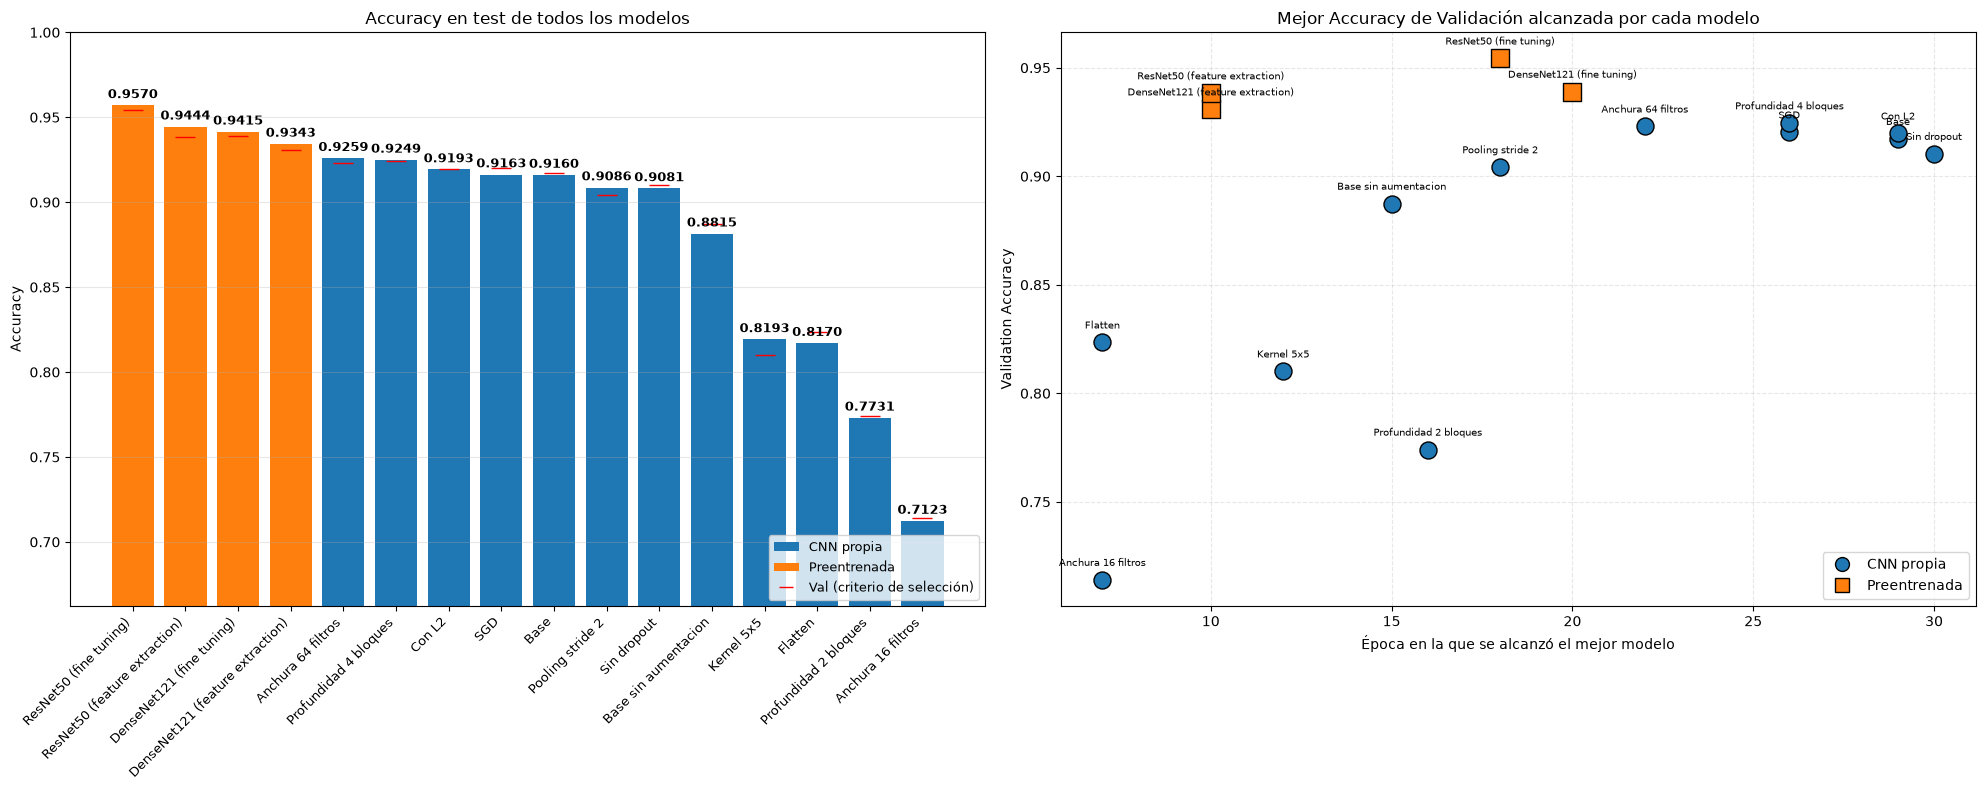

In [45]:
# Comparación entre modelos
COLORES = {False: "tab:blue", True: "tab:orange"}
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# datos para la gráfica 1
resultados_ordenados = sorted(resultados, key=lambda r: r["acc_test"], reverse=True)
nombres = [r["nombre"] for r in resultados_ordenados]
acc_test = [r["acc_test"] for r in resultados_ordenados]
acc_val = [r["acc_val"] for r in resultados_ordenados]
colores = [COLORES[r["preentrenado"]] for r in resultados_ordenados]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Gráfica izquierda : Barras (Test) + rayas (Val)
barras = ax1.bar(range(len(resultados_ordenados)), acc_test, color=colores)

# Imprimir valor de Test encima de cada barra
for barra, val in zip(barras, acc_test):
    ax1.annotate(f'{val:.4f}',
                 xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Marca de validación (raya roja)
ax1.plot(range(len(resultados_ordenados)), acc_val, linestyle="none", marker="_", markersize=15, color="red")

ax1.set_ylabel("Accuracy")
ax1.set_title("Accuracy en test de todos los modelos")
ax1.set_xticks(range(len(resultados_ordenados)))
ax1.set_xticklabels(nombres, rotation=45, ha="right", fontsize=9)
# Ajustamos el límite inferior para que quepan los números de validación si están muy bajos
ax1.set_ylim(min(min(acc_test), min(acc_val)) - 0.05, 1.0)
ax1.grid(alpha=0.3, axis="y")

# Leyenda Gráfica 1
ax1.legend(handles=[
    Patch(facecolor="tab:blue", label="CNN propia"),
    Patch(facecolor="tab:orange", label="Preentrenada"),
    Line2D([0], [0], color="red", marker="_", markersize=10, markeredgewidth=1, linestyle="None", label="Val (criterio de selección)"),
], loc="lower right", fontsize=9)


# Gráfica derecha: mejor validación
for r in resultados:
    h = r["historial"]
    # Encontramos la época con el mejor val_loss
    mejor_epoca = np.argmin(h["val_loss"])
    mejor_val_acc = h["val_accuracy"][mejor_epoca]
    
    color = "tab:blue" if r["preentrenado"] == False else "tab:orange"
    marcador = "o" if r["preentrenado"] == False else "s"
    
    ax2.scatter(mejor_epoca + 1, mejor_val_acc, color=color, marker=marcador, s=150, edgecolors='black', zorder=3)
    ax2.annotate(r["nombre"], 
                 (mejor_epoca + 1, mejor_val_acc), 
                 textcoords="offset points", 
                 xytext=(0, 10), # Desplaza el texto 10 puntos hacia arriba
                 ha='center', 
                 fontsize=7,     # Fuente pequeña para que no se solapen
                 zorder=4)       # Para que el texto se dibuje por encima del punto

ax2.set_title("Mejor Accuracy de Validación alcanzada por cada modelo")
ax2.set_xlabel("Época en la que se alcanzó el mejor modelo")
ax2.set_ylabel("Validation Accuracy")
ax2.grid(alpha=0.3, linestyle='--')

# Leyenda Gráfica 2
ax2.legend(handles=[
    Line2D([1], [1], marker='o', color='w', markerfacecolor='tab:blue', markeredgecolor='black', markersize=10, label='CNN propia'),
    Line2D([1], [1], marker='s', color='w', markerfacecolor='tab:orange', markeredgecolor='black', markersize=10, label='Preentrenada')
], loc='lower right')


plt.tight_layout()
plt.savefig(SALIDA / "fig_comparacion.png", dpi=150)
plt.show()

En estas gráficas se puede ver la accuracy de test y validación en la mejor época de cada modelo. En la gráfica de la izquierda está marcada con una línea en rojo la acurracy de validación, para poder comparar ambos valores visualmente (el valor que aparece en cada barra es la accuracy de test).

Como se puede ver, en la mayoría de redes ambos valores no varían significativamente, lo que demuestra que el conjunto de validación es representativo de los datos reales y los modelos no se han aprendido este conjunto. Las redes preentrenadas han conseguido los mejores valores en test (entre 0.95 y 0.93), seguidas de las redes con arquitecturas más complejas (64 filtros y 4 bloques). La base también obtiene una muy buena puntuación, lo que refuerza su elección como punto de partida para las comparaciones. 

Las redes más simples han conseguido peores valores, algo ya comprobado en sus curvas, porque la mayoría no son capaces de sacar patrones de los datos o demuestran overfitting, el cual hace que sus valores de test caigan drásticamente comparados con los del entrenamiento.

En cuanto a las pre entrenadas, ResNet ha funcionado mejor que Densenet, algo que se puede atribuír a las conexiones residuales que usa, que preservan mejor la información de la imagen, algo muy útil en datasets como el de eurosat. En cambio, densenet está más orientada a texturas y detalles finos, lo que puede llevar a una mayor sensibilidad al ruido en imágenes de baja resolución como las de este dataset.

Además, el fine tuning funcionó mucho mejor en ResNet que en DenseNet. En DenseNet, descongelar las capas no sirvió para mejorar la validación. Sin embargo, en ResNet50 sí permitió ajustar las últimas capas convolucionales a las imágenes de EuroSAT, consiguiendo el mejor resultado de test de todos los modelos(0.9570). Esto indica que las capas de ResNet50 son más flexibles y se adaptan mejor a las características de este dataset, mientras que las de DenseNet121 ya eran buenas desde el principio y no admitían mucha más mejora.

En la gráfica de la izquierda se puede ver la accuracy en validation del epoch donde cada modelo alcanzó su menor loss. Se ve que, aunque los modelos de L2, sin dropout y la base se podían haber beneficiado de un aumento del número de epochs, el resto se detuvieron por early stopping antes de alcanzar el máximo. Esta gráfica justifica el valor del número de epochs máximo (teniendo en cuenta los tiempos de entrenamiento). En cuanto a las preentrenadas, ambas agotaron su máximo de epochs (aunque en resnet fine tuning la mejor fuera la 18) al no modificar el valor de patience para ellas (5 epochs serían la mitad del total). Aunque se pudieran haber beneficiado de más epochs, se consideró que los valores alcanzados son suficientemente buenos como para compensar el tiempo de ejecución en caso de añadir más.

Mejor CNN propia    : Profundidad 4 bloques (val_acc = 0.9244)
Mejor preentrenada : ResNet50 (fine tuning) (val_acc = 0.9543)


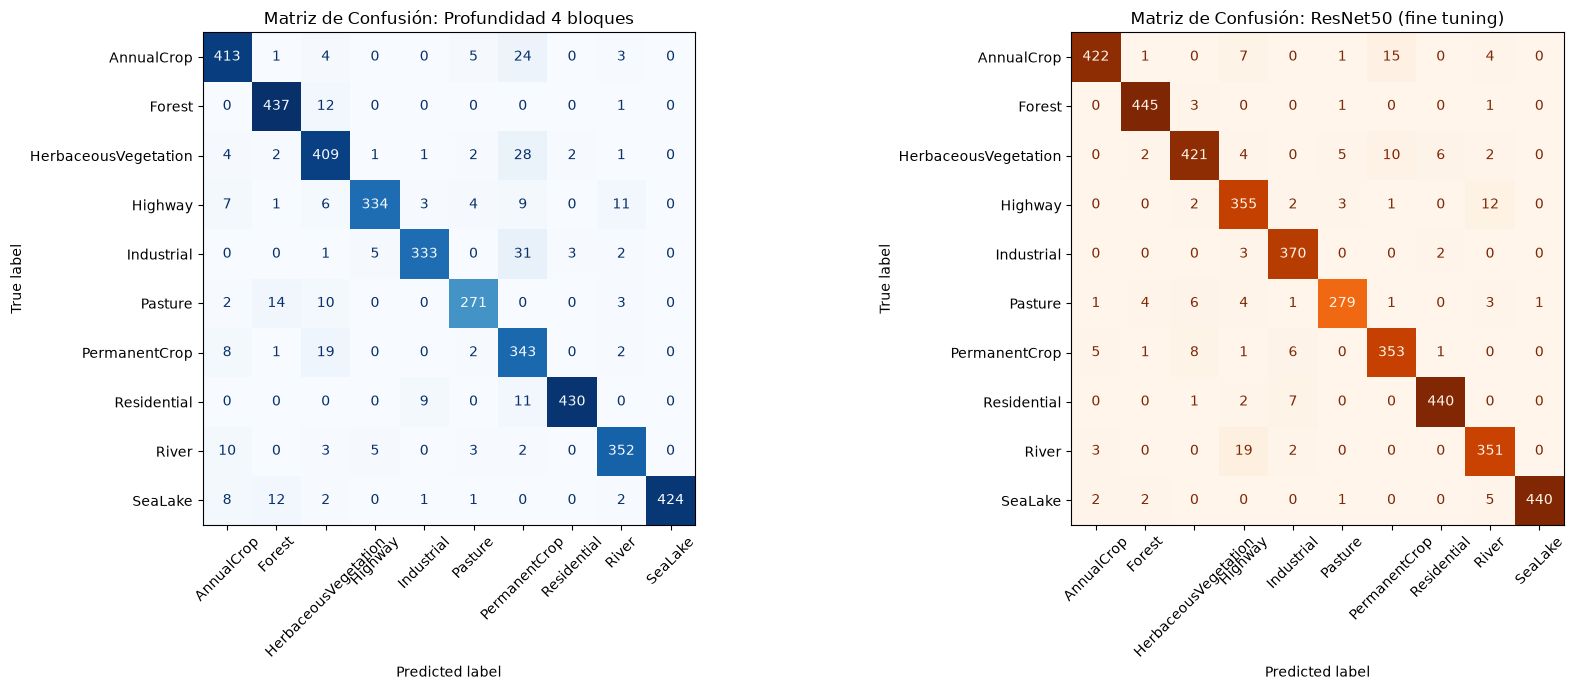

In [46]:
# %%
# COMPARACIÓN: MATRICES DE CONFUSIÓN LADO A LADO
from sklearn.metrics import ConfusionMatrixDisplay

mejor_custom = max([r for r in resultados if r["preentrenado"] == False], key=lambda r: r["acc_val"])
mejor_pre = max([r for r in resultados if r["preentrenado"] == True], key=lambda r: r["acc_val"])

print(f"Mejor CNN propia    : {mejor_custom['nombre']} (val_acc = {mejor_custom['acc_val']:.4f})")
print(f"Mejor preentrenada : {mejor_pre['nombre']} (val_acc = {mejor_pre['acc_val']:.4f})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Matriz del mejor modelo propio
matriz_custom = np.array(mejor_custom["matriz"])
disp1 = ConfusionMatrixDisplay(confusion_matrix=matriz_custom, display_labels=nombres_clases)
disp1.plot(ax=ax1, cmap="Blues", colorbar=False, xticks_rotation=45)
ax1.set_title(f"Matriz de Confusión: {mejor_custom['nombre']}")

# Matriz del mejor preentrenado
matriz_pre = np.array(mejor_pre["matriz"])
disp2 = ConfusionMatrixDisplay(confusion_matrix=matriz_pre, display_labels=nombres_clases)
disp2.plot(ax=ax2, cmap="Oranges", colorbar=False, xticks_rotation=45)
ax2.set_title(f"Matriz de Confusión: {mejor_pre['nombre']}")

plt.tight_layout()
plt.savefig(SALIDA / "fig_matrices_confusion.png", dpi=150)
plt.show()

Para analizar en detalle el comportamiento de los modelos, se comparan las matrices de confusión del mejor modelo propio (Profundidad 4) y del mejor modelo preentrenado (ResNet50 Fine-Tuning).

Se puede ver que la mayor fuente de error en ambos modelos es la confusión entre imágenes similares en cuanto a color y textura. En la red propia, a la arquitectura le cuesta distinguir annual crop, herbaceous vegetation y industrial de permanent crop, teniendo esta clase la mayor tasa de falsos positivos. En resnet los errores están más repartidos, y únicamente tiene falsos positivos en clases que, analizando el dataset, se puede ver que tienen ejemplos muy similares. Aún asi, las muestras mal clasificadas no suponen un conjunto muy grande respecto al total en ninguna de las dos redes, lo que se ve en el valor de test accuracy.

/tmp/ipykernel_9287/2903359823.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


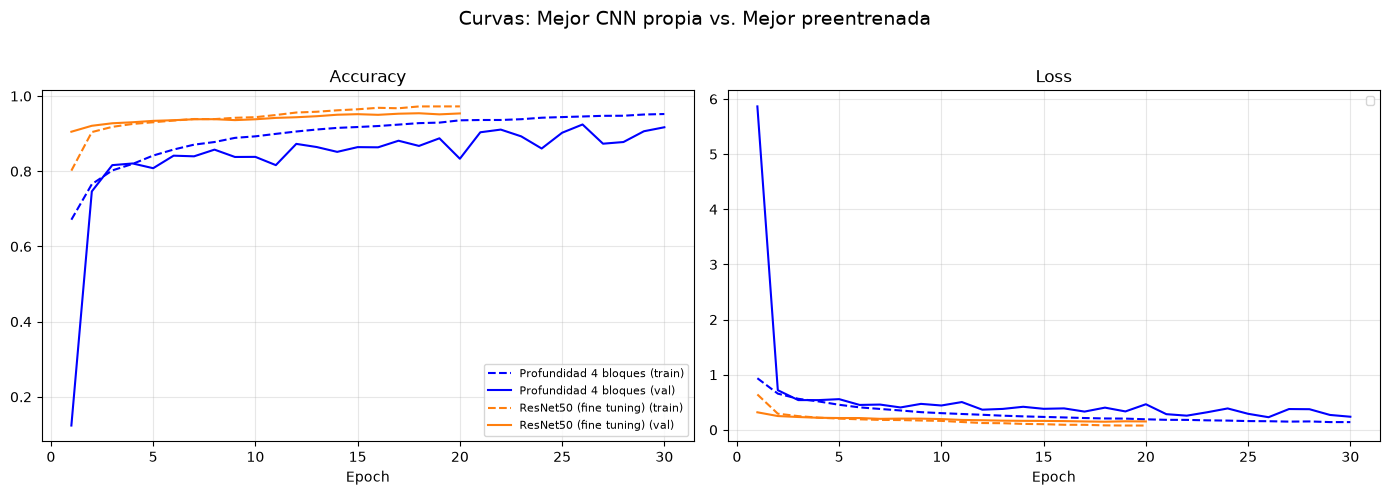

In [47]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# --- Curvas del mejor modelo propio (Azul) ---
h = mejor_custom["historial"]
ep = range(1, len(h["val_loss"]) + 1)
ejes[0].plot(ep, h["accuracy"], 'b--', label=f'{mejor_custom["nombre"]} (train)')
ejes[0].plot(ep, h["val_accuracy"], 'b-', label=f'{mejor_custom["nombre"]} (val)')
ejes[1].plot(ep, h["loss"], 'b--')
ejes[1].plot(ep, h["val_loss"], 'b-')

# --- Curvas del mejor modelo preentrenado (Naranja) ---
h = mejor_pre["historial"]
ep = range(1, len(h["val_loss"]) + 1)
ejes[0].plot(ep, h["accuracy"], color="tab:orange", linestyle='--', label=f'{mejor_pre["nombre"]} (train)')
ejes[0].plot(ep, h["val_accuracy"], color="tab:orange", linestyle='-', label=f'{mejor_pre["nombre"]} (val)')
ejes[1].plot(ep, h["loss"], color="tab:orange", linestyle='--')
ejes[1].plot(ep, h["val_loss"], color="tab:orange", linestyle='-')

ejes[0].set_title("Accuracy")
ejes[1].set_title("Loss")
for ax in ejes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Curvas: Mejor CNN propia vs. Mejor preentrenada", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(SALIDA / "fig_curvas_comparacion.png", dpi=150)
plt.show()

Aquí se pueden ver las curvas de entrenamiento de cada uno de los dos modelos. Se ve claramente la ventaja de resnet al partir de unos pesos ya entrenados en sus valores desde el inicio. En cambio, la red propia comienza con valores muy bajos de accuracy y altos de loss hasta que se estabiliza a partir de la epoch 25. 

Con esto se ve que, para este dataset en específico, aunque se puedan observar mejoras de utilizar una red ya entrenada para la clasificación, entrenar una desde 0 puede obtener resultados muy similares con menos coste computacional y parámetros. 